# ResNet残差网络

## ResNet出现的动机
1. 设 $\mathcal{F}$：网络架构对应的**函数族**（包含网络结构、所有超参；不同权重对应族内不同函数 f）

2. $f^*$：现实中真实映射（我们终极想要的理想函数）

3. $f^*_\mathcal{F} = \arg\min_{f\in\mathcal{F}} L(\boldsymbol{X},\boldsymbol{y},f)$

   

   在当前函数族 $\mathcal{F}$ 里面，能找到的
   最优拟合函数。

> 关键问题：想要逼近 $f^*$，扩充函数族一定会更好吗？

- 若新函数族 $\mathcal{F}'$ **嵌套包含原来的函数族**：$\mathcal{F} \subseteq \mathcal{F}'$

  $f^*_{\mathcal{F}'} \text{ 的损失} \le f^*_{\mathcal{F}} \text{ 的损失}$

  理由：原来最优的 $f^*_\mathcal{F}$ 依然在 $\mathcal{F}'$ 里面，算法至少可以选到旧最优解，性能不会变差。

- 若**非嵌套** $\mathcal{F}\not\subseteq\mathcal{F}'$

  更大 / 更复杂的函数族**没有任何保证**，新最优解 $f^*_{\mathcal{F}'}$ 甚至可以离 $f^*$ 更远。

> 放到深度网络里的现实痛点

我们直观想法：**堆更多网络层 → 模型更强**

把网络从 L 层加深到 $L+1$ 层。

记浅层网络函数族 $\mathcal{F}_L$，加深后 $\mathcal{F}_{L+1}$。

❌ 普通 CNN：$\boldsymbol{\mathcal{F}_L \nsubseteq \mathcal{F}_{L+1}}$

能不能把新增的一层学成**恒等映射** $h(\boldsymbol{x})=\boldsymbol{x}$?

普通堆叠网络很难做到！

新增层必须学习 $F(\boldsymbol{x})$，整体输出 $F(\text{浅层输出})$。

想要等价于浅层模型，必须强行学习 $F(z)=z$；

深层网络训练很难收敛到恒等映射，优化困难。

结果：加深网络之后，理论上容量更大，但**训练效果反而变差（退化问题 degradation）**。

> ResNet 残差块的解决思路（核心创新）

假设原有浅层网络输出是 $\boldsymbol{x}$。

新增层不去直接拟合最终映射 $H(\boldsymbol{x})$，

改为拟合**残差映射**：

$H(\boldsymbol{x}) = \boldsymbol{x} + F(\boldsymbol{x})$

$\Rightarrow F(\boldsymbol{x}) = H(\boldsymbol{x}) - \boldsymbol{x}$

前向传播：

$\boldsymbol{y} = \boldsymbol{x} + F(\boldsymbol{x})$

>  为什么这样就实现嵌套 $\mathcal{F}_L \subseteq \mathcal{F}_{L+1}$？

我们希望加深后的网络**至少拥有浅层网络全部能力**：

只需要让残差分支 $F(\boldsymbol{x})=\boldsymbol{0}$（全部权重置 0）。

此时：

$\boldsymbol{y} = \boldsymbol{x} + \boldsymbol{0} = \boldsymbol{x}$

新增模块等价于恒等映射！

👉 加深后的网络天然包含浅层网络全部解空间。

> 通俗总结：
>
> 普通网络加深：新增层学不好恒等映射，模型能力不保证提升；
>
> 残差连接：想退化成浅网络，只需要把残差分支学成 0，极其容易实现。
>
> 因此深层 ResNet 的函数族**嵌套浅层函数族**，保证：深层模型最优解不会比浅层更差。

## **残差块**

让我们聚焦于神经网络局部：如图 :numref:`fig_residual_block`所示，假设我们的原始输入为$x$，而希望学出的理想映射为$f(\mathbf{x})$（作为 :numref:`fig_residual_block`上方激活函数的输入）。
 :numref:`fig_residual_block`左图虚线框中的部分需要直接拟合出该映射$f(\mathbf{x})$，而右图虚线框中的部分则需要拟合出残差映射$f(\mathbf{x}) - \mathbf{x}$。
残差映射在现实中往往更容易优化。
以本节开头提到的恒等映射作为我们希望学出的理想映射$f(\mathbf{x})$，我们只需将 :numref:`fig_residual_block`中右图虚线框内上方的加权运算（如仿射）的权重和偏置参数设成0，那么$f(\mathbf{x})$即为恒等映射。
实际中，当理想映射$f(\mathbf{x})$极接近于恒等映射时，残差映射也易于捕捉恒等映射的细微波动。
 :numref:`fig_residual_block`右图是ResNet的基础架构--*残差块*（residual block）。
在残差块中，输入可通过跨层数据线路更快地向前传播。

![一个正常块（左图）和一个残差块（右图）。](../machine_learning_note\img\residual-block.svg)
:label:`fig_residual_block`

ResNet沿用了VGG完整的$3\times 3$卷积层设计。
残差块里首先有2个有相同输出通道数的$3\times 3$卷积层。
每个卷积层后接一个批量规范化层和ReLU激活函数。
然后我们通过跨层数据通路，跳过这2个卷积运算，将输入直接加在最后的ReLU激活函数前。
这样的设计要求2个卷积层的输出与输入形状一样，从而使它们可以相加。
如果想改变通道数，就需要引入一个额外的$1\times 1$卷积层来将输入变换成需要的形状后再做相加运算。
残差块的实现如下：


In [2]:
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, use_1x1conv = False, stride = 1):
        super().__init__()
        # 残差分支
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size = 3, padding = 1, stride = stride)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size = 3, padding = 1)
        # shortcut通路
        if use_1x1conv:
            self.conv3 = nn.Conv2d(in_channels, out_channels, kernel_size =1, stride = stride)
        else:
            self.conv3 = None
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.bn2 = nn.BatchNorm2d(out_channels)
    def forward(self, X):
        Y = self.bn2(self.conv2(F.relu(self.bn1(self.conv1(X)))))
        if self.conv3:
            X = self.conv3(X)
        # 残差连接
        Y += X
        return F.relu(Y)

如 :numref:`fig_resnet_block`所示，此代码生成两种类型的网络：
一种是当`use_1x1conv=False`时，应用ReLU非线性函数之前，将输入添加到输出。
另一种是当`use_1x1conv=True`时，添加通过$1 \times 1$卷积调整通道和分辨率。

![包含以及不包含 $1 \times 1$ 卷积层的残差块。](../machine_learning_note\img\resnet-block.svg)
:label:`fig_resnet_block`

下面我们来查看[**输入和输出形状一致**]的情况。

In [28]:
blk = ResidualBlock(3,3)
X = torch.rand(4, 3, 6, 6)
Y = blk(X)
Y.shape

torch.Size([4, 3, 6, 6])

我们也可以在[**增加输出通道数的同时，减半输出的高和宽**]。

In [29]:
blk = ResidualBlock(3,6, use_1x1conv=True, stride=2)
blk(X).shape

torch.Size([4, 6, 3, 3])

## ResNet网络
ResNet的前两层跟之前介绍的GoogLeNet中的一样：
在输出通道数为64、步幅为2的$7 \times 7$卷积层后，接步幅为2的$3 \times 3$的最大汇聚层。
不同之处在于ResNet每个卷积层后增加了批量规范化层。

In [30]:
b1 = nn.Sequential(nn.Conv2d(1, 64, kernel_size = 7, stride = 2, padding = 3),
                   nn.BatchNorm2d(64),
                   nn.ReLU(),
                   nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1))

GoogLeNet在后面接了3个由Inception块组成的模块。
ResNet则使用4个由残差块组成的模块，每个模块使用若干个同样输出通道数的残差块。
第一个模块的通道数同输入通道数一致。
由于之前已经使用了步幅为2的最大汇聚层，所以无须减小高和宽。
之后的每个模块在第一个残差块里将上一个模块的通道数翻倍，并将高和宽减半。

下面我们来实现这个模块。注意，我们对第一个模块做了特别处理。

In [31]:
def resnet_block(in_channels, out_channels, num_residuals, first_block = False):
    blk = []
    for i in range(num_residuals):
        if i == 0 and not first_block:
            blk.append(ResidualBlock(in_channels, out_channels, use_1x1conv = True, stride = 2))
        else:
            blk.append(ResidualBlock(out_channels, out_channels))
    return blk

接着在ResNet加入所有残差块，这里每个模块使用2个残差块。

In [32]:
b2 = nn.Sequential(*resnet_block(64, 64, 2, first_block = True))
b3 = nn.Sequential(*resnet_block(64, 128, 2))
b4 = nn.Sequential(*resnet_block(128, 256, 2))
b5 = nn.Sequential(*resnet_block(256, 512, 2))

最后，与GoogLeNet一样，在ResNet中加入全局平均汇聚层，以及全连接层输出。

In [33]:
net = nn.Sequential(b1, b2, b3, b4, b5,
                    nn.AdaptiveAvgPool2d((1,1)),
                    nn.Flatten(), nn.Linear(512, 10))

每个模块有4个卷积层（不包括恒等映射的$1\times 1$卷积层）。
加上第一个$7\times 7$卷积层和最后一个全连接层，共有18层。
因此，这种模型通常被称为ResNet-18。
通过配置不同的通道数和模块里的残差块数可以得到不同的ResNet模型，例如更深的含152层的ResNet-152。
虽然ResNet的主体架构跟GoogLeNet类似，但ResNet架构更简单，修改也更方便。这些因素都导致了ResNet迅速被广泛使用。
 :numref:`fig_resnet18`描述了完整的ResNet-18。

![ResNet-18 架构](../machine_learning_note\img\resnet18.svg)
:label:`fig_resnet18`

在训练ResNet之前，让我们[**观察一下ResNet中不同模块的输入形状是如何变化的**]。
在之前所有架构中，分辨率降低，通道数量增加，直到全局平均汇聚层聚集所有特征。

In [34]:
X = torch.rand(size=(1, 1, 224, 224))
for layer in net:
    X = layer(X)
    print(layer.__class__.__name__,'output shape:\t', X.shape)

Sequential output shape:	 torch.Size([1, 64, 56, 56])
Sequential output shape:	 torch.Size([1, 64, 56, 56])
Sequential output shape:	 torch.Size([1, 128, 28, 28])
Sequential output shape:	 torch.Size([1, 256, 14, 14])
Sequential output shape:	 torch.Size([1, 512, 7, 7])
AdaptiveAvgPool2d output shape:	 torch.Size([1, 512, 1, 1])
Flatten output shape:	 torch.Size([1, 512])
Linear output shape:	 torch.Size([1, 10])


loss 0.016, train acc 0.996, test acc 0.917
747.8 examples/sec on cuda:0


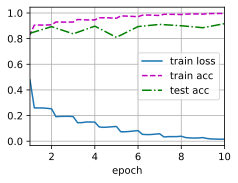

In [35]:
lr, num_epochs, batch_size = 0.05, 10, 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size, resize=96)
d2l.train_ch6(net, train_iter, test_iter, num_epochs, lr, d2l.try_gpu())

# Deep Residual Learning for Image Recognition
## Introduction
Driven by the significance of depth , a question arises: *Is learning better networks as easy as stacking more layers?*

> problem1: **vanishing / exploding gradients**, which hamper convergence from the beginning
>
> addressed：parameter initialization and  intermediate normalization
>
> problem2: *degradation*, and this problem is not caused by overfitting
>
> addressed: **deep residual learning framework**

## Related Work
* **Residual Representations**：based on traditional handing methods, such as VLAD，Fisher Vector.已经证明过残差拟合更容易了。还给了PDEs解偏微分方程的例子，多重网格法的替代方案是 hierarchical basis preconditioning.已有研究证明，这类求解器相比无视解的残差特性的标准求解器，收敛速度要快很多。These methods suggest that a good reformulation or preconditioning can simplify the optimization.
* **Shortcut Connections**: 早期的MLPs直接将输入和输出连接的线性捷径，GoogLeNet中的Inception块，辅助分类器，Highway networks中的门控捷径
## Deep Residual Learning
### Residual Learning
为什么残差连接优化速度会加快，我觉得一个重要原因是当网络很深时，此时的输入特征本身已经足够好，残差分支几乎不需要修改，或者相当于给优化器一个初始的优化标准，大幅降低拟合难度

具体来说就是学习权重为0比直接学恒等映射更容易
### Identity Mapping by Shortcut
 输出通道变化时加入1 $\times$ 1卷积层
### NetWork architecture
当输出通道发生变化时

* option A：Identity恒等捷径，padding with zero
* option B: Projection投影捷径，1 $\times$ 1 卷积层
### Inplemention
* scale augmentation(horizontal flip), with per-pixel mean subtracted
* standard color augmentation
* The learning rate starts from 0.1 and is divided by 10 when the error plateaus.
* use a weight decay of 0.0001 and a momentum of 0.9
* do not use dropout
### Experiments
#### Deeper **Bottleneck** Architectures

核心：**降维-卷积-升维**
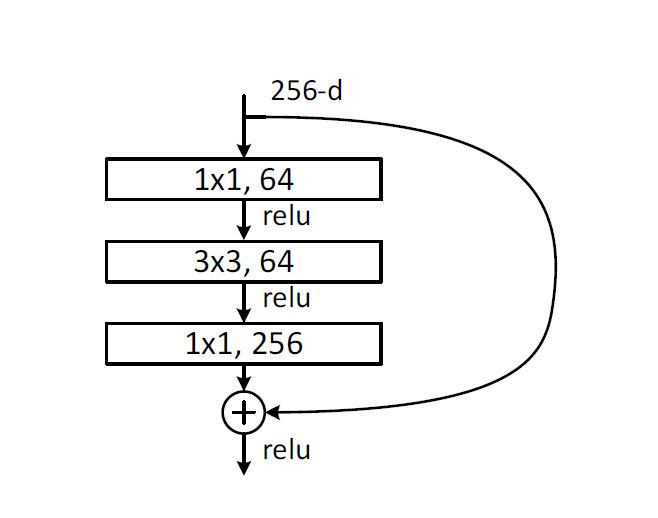

In [2]:
# Resnet-50
class BottleNeck(nn.Module):
    expansion = 4
    def __init__(self, in_channels, mid_channels, stride = 1, downsample = False):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, mid_channels, kernel_size = 1, bias = False)
        self.conv2 = nn.Conv2d(mid_channels, mid_channels, kernel_size = 3, padding = 1, stride = stride, bias = False)
        self.conv3 = nn.Conv2d(mid_channels, mid_channels * self.expansion, kernel_size = 1, bias = False)
        self.bn1 = nn.BatchNorm2d(mid_channels)
        self.bn2 = nn.BatchNorm2d(mid_channels)
        self.bn3 = nn.BatchNorm2d(mid_channels * self.expansion)
        if downsample:
            self.conv4 = nn.Conv2d(in_channels, mid_channels * self.expansion , kernel_size = 1, stride = stride)
        else:
            self.conv4 = None
    def forward(self, X):
        out = F.relu(self.bn1(self.conv1(X)))
        out = F.relu(self.bn2(self.conv2(out)))
        Y = self.bn3(self.conv3(out))
        if self.conv4:
            X = self.conv4(X)
        Y += X
        return F.relu(Y)

In [3]:
b1 = nn.Sequential(nn.Conv2d(1, 64, kernel_size = 7, stride = 2, padding = 3),
                   nn.BatchNorm2d(64),
                   nn.ReLU(),
                   nn.MaxPool2d(kernel_size = 3, stride = 2))

In [4]:
def deeper_resnet_block(in_channels, mid_channels, num_residuals, first_block = False):
    blk = []
    for i in range(num_residuals):
        if i == 0 and not first_block:
            blk.append(BottleNeck(in_channels, mid_channels, stride = 2, downsample = True))
        elif i == 0:
            blk.append(BottleNeck(in_channels, mid_channels, downsample = True))
        else:
            blk.append(BottleNeck(mid_channels * 4, mid_channels))
    return blk

In [5]:
b2 = nn.Sequential(*deeper_resnet_block(64, 64, 3, first_block = True))
b3 = nn.Sequential(*deeper_resnet_block(256, 128, 4))
b4 = nn.Sequential(*deeper_resnet_block(512, 256, 6))
b5 = nn.Sequential(*deeper_resnet_block(1024, 512, 3))
resnet50 = nn.Sequential(b1, b2, b3, b4, b5, nn.AdaptiveAvgPool2d((1, 1)),
                         nn.Flatten(), nn.Linear(2048, 10))
X = torch.rand(size=(1, 1, 224, 224))
for layer in resnet50:
    X = layer(X)
    print(layer.__class__.__name__,'output shape:\t', X.shape)

Sequential output shape:	 torch.Size([1, 64, 55, 55])
Sequential output shape:	 torch.Size([1, 256, 55, 55])
Sequential output shape:	 torch.Size([1, 512, 28, 28])
Sequential output shape:	 torch.Size([1, 1024, 14, 14])
Sequential output shape:	 torch.Size([1, 2048, 7, 7])
AdaptiveAvgPool2d output shape:	 torch.Size([1, 2048, 1, 1])
Flatten output shape:	 torch.Size([1, 2048])
Linear output shape:	 torch.Size([1, 10])


loss 0.150, train acc 0.945, test acc 0.866
687.9 examples/sec on cuda:0


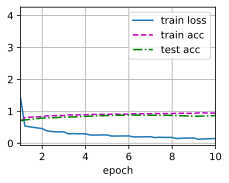

In [6]:
# 轻量化版本，最高通道1024
b1 = nn.Sequential(nn.Conv2d(1, 32, kernel_size = 7, stride = 2, padding = 3,bias=False),
                   nn.BatchNorm2d(32),
                   nn.ReLU(),
                   nn.MaxPool2d(kernel_size = 3, stride = 2))

b2 = nn.Sequential(*deeper_resnet_block(32, 32, 3, first_block = True))
b3 = nn.Sequential(*deeper_resnet_block(128, 64, 4))
b4 = nn.Sequential(*deeper_resnet_block(256, 128, 6))
b5 = nn.Sequential(*deeper_resnet_block(512, 256, 3))

light_resnet50 = nn.Sequential(b1,b2,b3,b4,b5,
                             nn.AdaptiveAvgPool2d((1,1)),
                             nn.Flatten(),
                             nn.Dropout(0.2),
                             nn.Linear(1024,10))
lr, num_epochs, batch_size = 0.05, 10, 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size, resize=96)
d2l.train_ch6(light_resnet50, train_iter, test_iter, num_epochs, lr, d2l.try_gpu())

# Identity Mappings in Deep Residual Learning
## Abstract
propose a new residual unit, which makes training easier and improves generalization.
## Introduction
clean information path：收敛速度最快，最低训练损失（捷径路上加上任何变换都会损害优化，要尽可能维持纯净的直传通路，只有维度不匹配的时候才不得已使用投影）
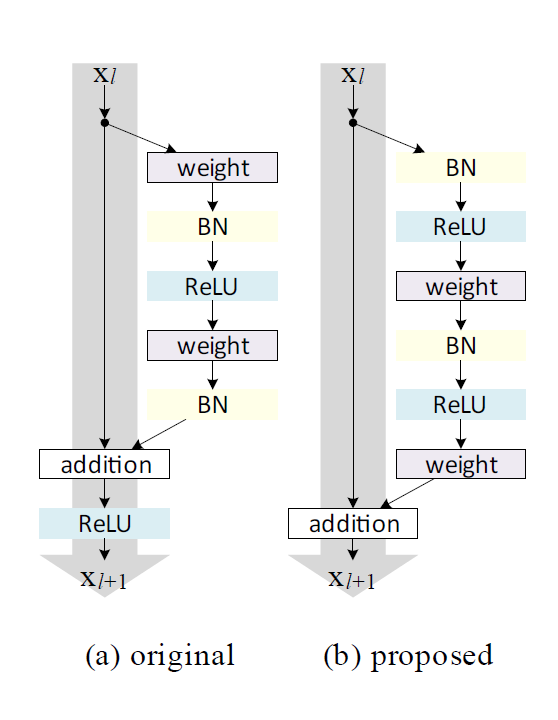
## Analysis of Deep Residual Networks

$$
x_L = x_l + \sum_{i=l}^{L-1} F(x_i;W_i)
$$
* **任意两个残差单元之间都满足残差累加关系**。
* 深层特征等于原始输入 $x_0$ 再叠加前面所有残差分支输出。
这和普通网络形成鲜明对比：忽略BN与ReLU时，普通网络的特征是一系列矩阵‑向量连乘：
$$
x_L=\prod_{i=0}^{L-1} W_i x_0
$$
* 反向传播：
$$
\frac{\partial E}{\partial x_l}
=\frac{\partial E}{\partial x_L}\frac{\partial x_L}{\partial x_l}
=\frac{\partial E}{\partial x_L}\left(
1+\frac{\partial}{\partial x_l}\sum_{i=l}^{L-1}F(x_i;W_i)
\right)
$$
大大减少了梯度消失的可能

## On the importance of identity mapping
$$
x_{l+1}=\lambda_l x_l + F(x_l;W_l) \tag{6}
$$
其中 $\lambda_l$ 为调节标量（为简化分析，仍假设残差分支输出之后的映射 $f$ 是恒等映射）。

反向传播梯度为：
$$
\frac{\partial E}{\partial x_l}=
\frac{\partial E}{\partial x_L}\left(
\prod_{i=l}^{L-1}\lambda_i
+\frac{\partial}{\partial x_l}\sum_{i=l}^{L-1}\hat F(x_i;W_i)
\right) \tag{8}
$$
对于极深网络（$L$ 很大）：
- 如果全部 $\lambda_i>1$，该连乘系数会指数级增大；
- 如果全部 $\lambda_i<1$，该连乘系数会指数级变小直至趋近于0。

门控机制也是一样

Highway Network **互斥门控**单元公式
$$
x_{l+1}=g(x_l)\cdot x_l+\big(1-g(x_l)\big)\cdot F(x_l)
$$

- $g(x_l) = \sigma(W_g x_l + b_g)$，sigmoid输出，$\boldsymbol{g(x)\in[0,1]}$
- $g \to 1$：$x_{l+1}\approx x_l$，几乎完全走 shortcut 通路，残差分支 $F$ 被抑制
- $g \to 0$：$x_{l+1}\approx F(x_l)$，shortcut通路被关闭，几乎完全走变换分支 $F$

一些实验（scaling, gating, shortcut-only gating, 1x1conv）表明，即便有些变化获得了更多的参数，但是不一定参数更多性能更好，因为表征能力强不一定能够顺利优化到最优情况。**SGD 优化器很难找到那个好的最优解，陷入了不好的局部解**。

## On the Usage of Activation Functions
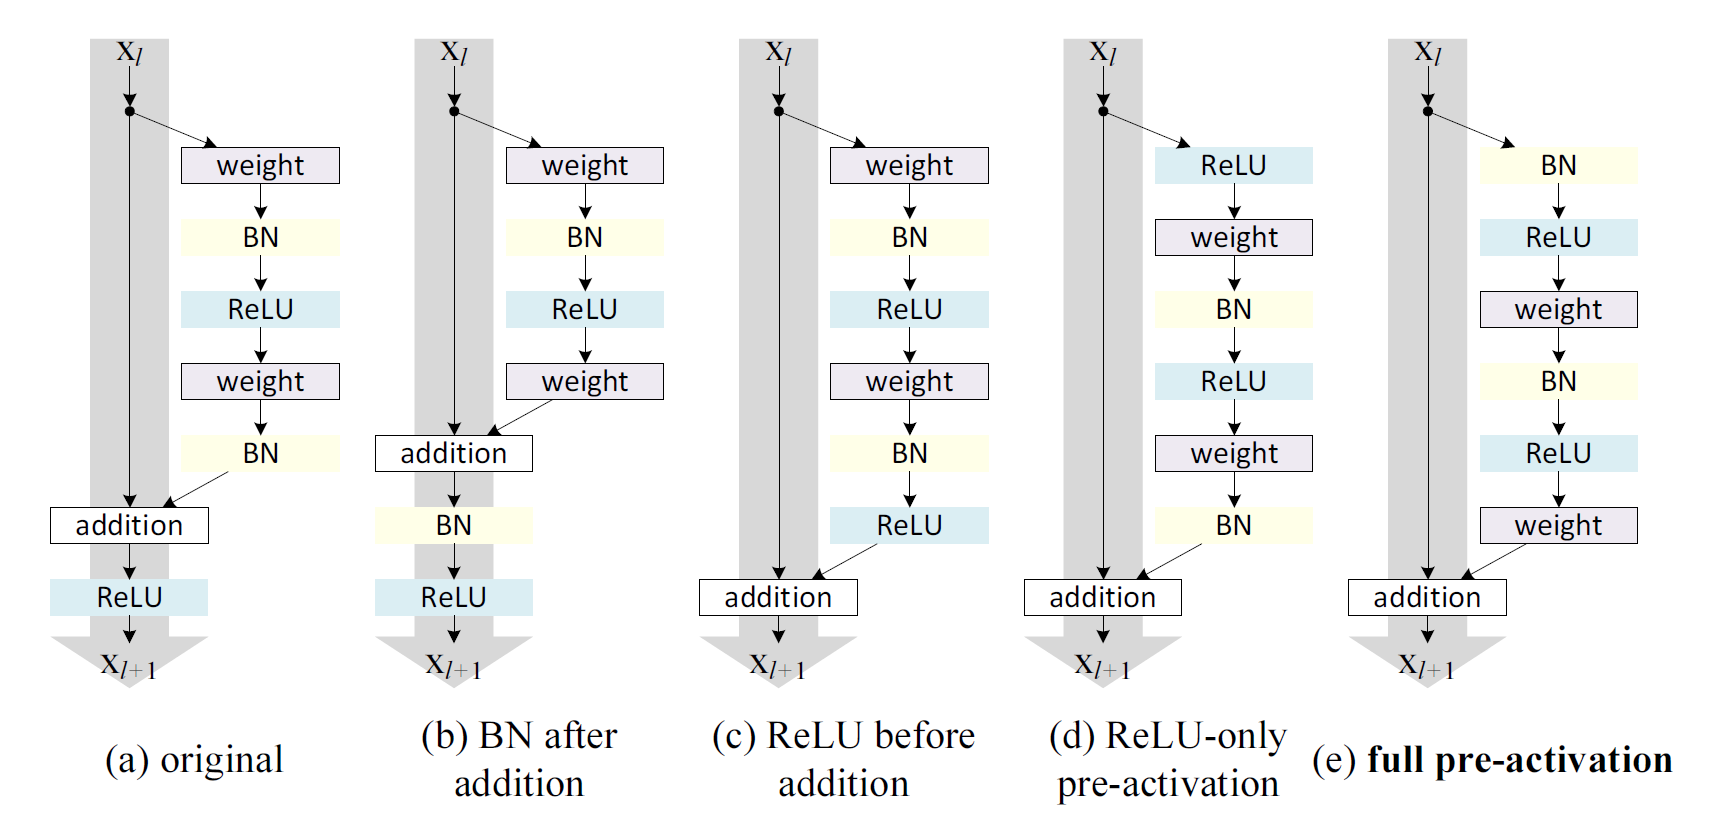

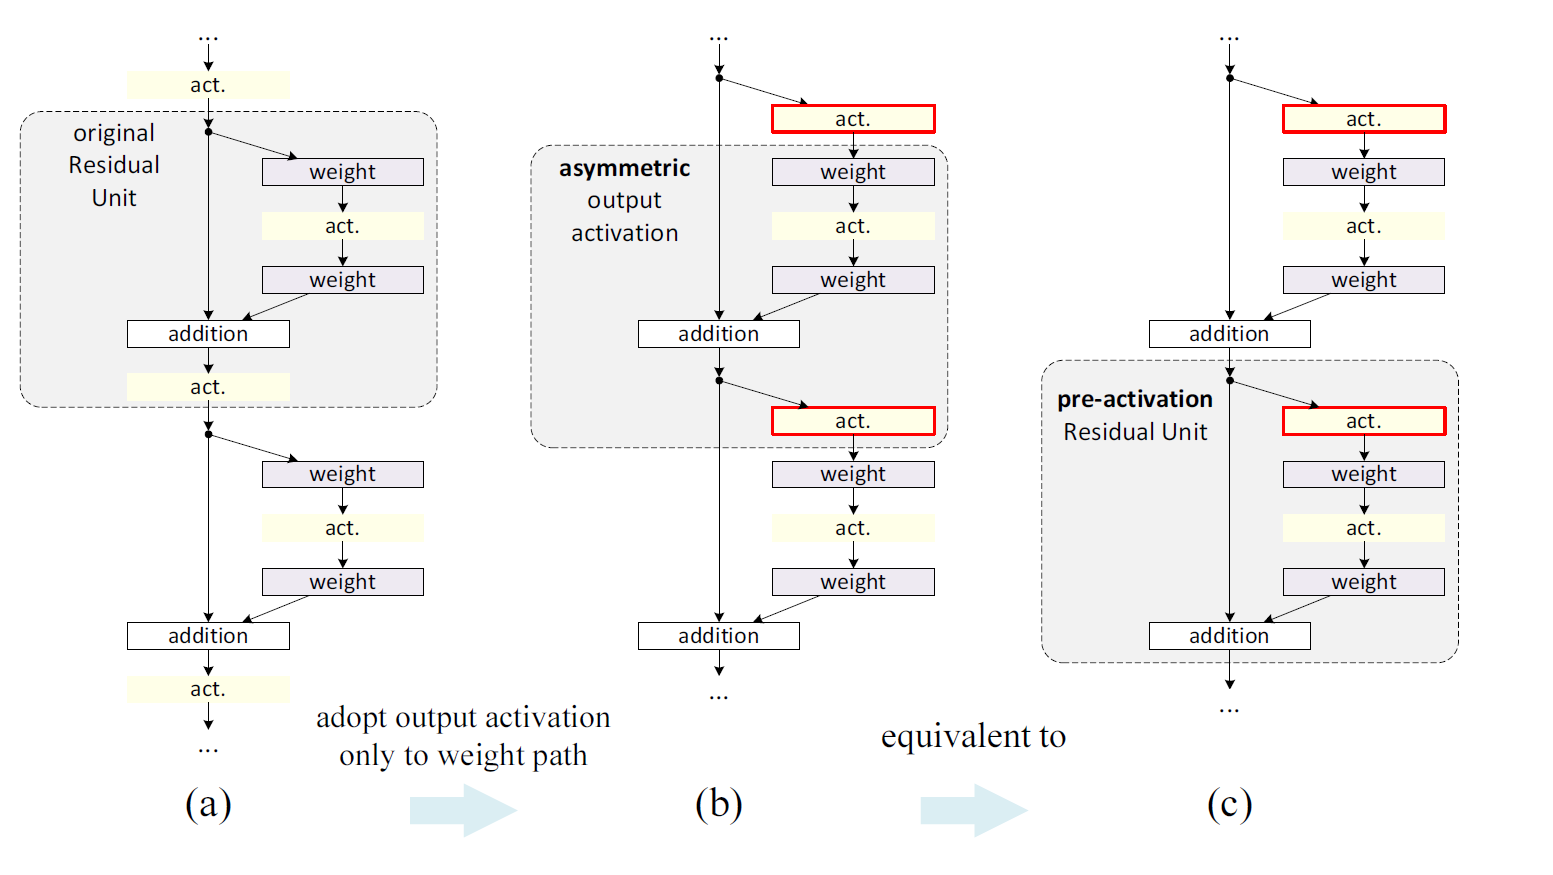

In [12]:
class PreActivationResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride = 1, downsample = False):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size = 3, padding = 1, stride = stride, bias = False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size = 3, padding = 1, bias = False)
        if downsample:
            self.conv3 = nn.Conv2d(in_channels, out_channels, kernel_size = 1, stride = stride, bias = False)
        else:
            self.conv3 = None
    def forward(self, X):
        Y = self.conv2(F.relu(self.bn2(self.conv1(F.relu(self.bn1(X))))))
        if self.conv3:
            X = self.conv3(X)
        return Y + X
def resnet_block_pre(in_channels, out_channels, num_residuals, first_block = False):
    blk = []
    for i in range(num_residuals):
        if i == 0 and not first_block:
            blk.append(PreActivationResidualBlock(in_channels, out_channels, stride = 2, downsample = True))
        else:
            blk.append(PreActivationResidualBlock(out_channels, out_channels))
    return blk


In [13]:
b1 = nn.Sequential(nn.Conv2d(1, 64, kernel_size = 7, stride = 2, padding = 3, bias = False),
                   nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1))
b2 = nn.Sequential(*resnet_block_pre(64, 64, 2, first_block = True))
b3 = nn.Sequential(*resnet_block_pre(64, 128, 2))
b4 = nn.Sequential(*resnet_block_pre(128, 256, 2))
b5 = nn.Sequential(*resnet_block_pre(256, 512, 2))
pre_activation_net = nn.Sequential(b1, b2, b3, b4, b5,
                    nn.AdaptiveAvgPool2d((1,1)),
                    nn.Flatten(), nn.Linear(512, 10))

loss 0.112, train acc 0.964, test acc 0.899
707.2 examples/sec on cuda:0


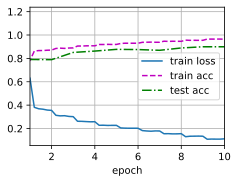

: 

In [ ]:
lr, num_epochs, batch_size = 0.01, 10, 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size, resize=96)
d2l.train_ch6(pre_activation_net, train_iter, test_iter, num_epochs, lr, d2l.try_gpu())